# Extended Data Fig. 14: CA1 d2 and branching ratio vs maze performance (first acquisition epoch)

Here: remove within-animal outliers → mixed model
`performance ~ measure + (1 | animal)` 

In [1]:
import os
import warnings

import matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from matplotlib.lines import Line2D
from scipy import stats
from statsmodels.tools.sm_exceptions import ConvergenceWarning

DATA = '../csv/FigS14_d2_br_performance/behavior_report_data.csv'
FIGDIR = '../figure_output/supplementary/FigS14'
os.makedirs(FIGDIR, exist_ok=True)
for f in ['Regular', 'Bold']:   # Helvetica clone (Nimbus Sans), embedded as TrueType in the PDF
    fm.fontManager.addfont(f'fonts/NimbusSans-{f}.ttf')

MEASURES = {'d2': 'CA1 d2', 'm': 'Branching ratio m (pyr)'}              # rows of the figure
WINDOWS = {'startbox': 'Start box ', 'running': 'Running '}
OUTCOMES = {'cum_dist': 'norm path length', 'time': 'norm. time'}

## Load the data (first acquisition epoch of each session)

In [2]:
df = pd.read_csv(DATA)
acq1 = df

## Statistics


In [3]:
def remove_outliers(d):
    for v in ('x', 'y'):
        med = d.groupby('animal')[v].transform('median')
        mad = (d[v] - med).abs().groupby(d.animal).transform('median') * 1.4826
        d = d[(d[v] - med).abs() <= 3 * mad]
    return d[d.groupby('animal').animal.transform('size') >= 3]     # keep animals with >= 3 epochs


def fit_lme(d):
    """y ~ x + (1 | animal); returns the fit, the slope SE and its p (Wald)."""
    model = smf.mixedlm('y ~ x', d, groups=d['animal'])
    best = None
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        warnings.simplefilter('ignore', RuntimeWarning)
        warnings.simplefilter('ignore', UserWarning)   # 'random effects covariance is singular': an optimizer
                                                       # put the animal variance at 0; harmless, best fit kept
        for method in ['lbfgs', 'bfgs', 'powell', 'nm']:
            try:
                f = model.fit(reml=True, method=method)
            except Exception:
                continue
            if np.isfinite(f.llf) and (best is None or f.llf > best.llf + 1e-9):
                best = f
    # slope SE from the GLS information matrix: (sum over animals of X' V^-1 X)^-1, V = s2 I + t2 J
    s2, t2 = float(best.scale), float(best.cov_re.iloc[0, 0])
    M = np.zeros((2, 2))
    for _, g in d.groupby('animal'):
        X = np.c_[np.ones(len(g)), g['x'].to_numpy(float)]
        n = len(g)
        V_inv = (np.eye(n) - t2 / (s2 + n * t2) * np.ones((n, n))) / s2
        M += X.T @ V_inv @ X
    se = float(np.sqrt(np.linalg.inv(M)[1, 1]))
    return best, se, 2 * stats.norm.sf(abs(best.params['x'] / se))


rows, panels = [], {}
for meas in MEASURES:
    for w in WINDOWS:
        for out in OUTCOMES:
            d = pd.DataFrame({'x': acq1[f'{meas}_{w}'], 'y': acq1[out], 'animal': acq1.animal}).dropna()
            d = remove_outliers(d)
            fit, se, p = fit_lme(d)
            rho, p_rho = stats.spearmanr(d.x, d.y)
            panels[(meas, w, out)] = (d, fit)
            rows.append({'measure': meas, 'window': w, 'outcome': out, 'n': len(d), 'LME slope': fit.params['x'],
                         'LME SE': se, 'LME p': p, 'pooled rho': rho, 'pooled p': p_rho})
res = pd.DataFrame(rows)

## Figure
Dots: epochs. Black solid: mixed-model fit (population line). Grey: the same slope with each animal's intercept.
Black dashed: least-squares fit over all epochs. Panel titles: mixed-model slope β and p; pooled Spearman r and p
(bold and *, mixed-model p < 0.05).

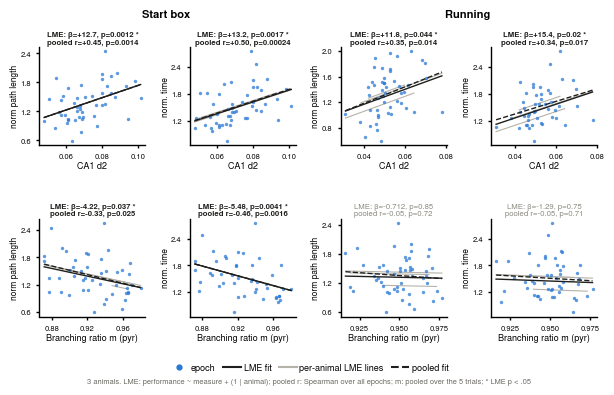

In [4]:
RC = {'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Nimbus Sans TT', 'Arial'], 'font.size': 7,
      'axes.linewidth': 1, 'xtick.major.width': 1, 'ytick.major.width': 1, 'xtick.major.size': 2.5,
      'ytick.major.size': 2.5, 'pdf.fonttype': 42, 'axes.spines.top': False, 'axes.spines.right': False}
BLUE, GREY, BLACK, MUTED = '#2a78d6', '#b4b2a9', '#1f1f1d', '#8a887f'

with plt.rc_context(RC):
    fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.5), gridspec_kw={'wspace': 0.42, 'hspace': 0.75})
    cols = [(w, o) for w in WINDOWS for o in OUTCOMES]
    for i, meas in enumerate(MEASURES):
        for j, (w, out) in enumerate(cols):
            ax = axes[i, j]
            d, fit = panels[(meas, w, out)]
            r = res[(res.measure == meas) & (res.window == w) & (res.outcome == out)].iloc[0]
            b0, b1 = fit.params['Intercept'], fit.params['x']
            ax.scatter(d.x, d.y, s=6, color=BLUE, alpha=0.75, lw=0, zorder=2)
            for animal, g in d.groupby('animal'):                       # per-animal lines (own intercept)
                xs = np.linspace(g.x.min(), g.x.max(), 20)
                u = fit.random_effects[animal].iloc[0]
                ax.plot(xs, b0 + u + b1 * xs, color=GREY, lw=0.8, zorder=1)
            xs = np.linspace(d.x.min(), d.x.max(), 20)
            ax.plot(xs, b0 + b1 * xs, color=BLACK, lw=1, zorder=4)            # mixed-model fit
            ax.plot(xs, np.polyval(np.polyfit(d.x, d.y, 1), xs), color=BLACK, lw=1, ls='--', zorder=4)   # pooled
            sig = r['LME p'] < 0.05
            ax.set_title(f"LME: β={b1:+.3g}, p={r['LME p']:.2g}" + (' *' if sig else '')
                         + f"\npooled r={r['pooled rho']:+.2f}, p={r['pooled p']:.2g}",
                         fontsize=5.6, pad=2, linespacing=1.15, fontweight='bold' if sig else 'normal',
                         color=BLACK if sig else MUTED)
            ax.set_xlabel(MEASURES[meas], fontsize=6.5, labelpad=1)
            ax.set_ylabel(OUTCOMES[out], fontsize=6, labelpad=1)
            ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(3))
            ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(4))
            ax.tick_params(labelsize=5.5)
    fig.canvas.draw()
    for j0, j1, (w, title) in [(0, 1, list(WINDOWS.items())[0]), (2, 3, list(WINDOWS.items())[1])]:
        x0, x1 = axes[0, j0].get_position().x0, axes[0, j1].get_position().x1
        fig.text((x0 + x1) / 2, axes[0, j0].get_position().y1 + 0.085, title, ha='center', fontsize=8,
                 fontweight='bold')
    handles = [Line2D([], [], marker='o', ls='', color=BLUE, ms=3.5, label='epoch'),
               Line2D([], [], color=BLACK, label='LME fit'),
               Line2D([], [], color=GREY, label='per-animal LME lines'),
               Line2D([], [], color=BLACK, ls='--', label='pooled fit')]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=4, frameon=False, fontsize=6.5,
               handletextpad=0.3, columnspacing=0.8)
    fig.text(0.5, -0.08, f'{acq1.animal.nunique()} animals. LME: performance ~ measure + '
             '(1 | animal); pooled r: Spearman over all epochs; m: pooled over the 5 trials; * LME p < .05',
             ha='center', fontsize=5.4, color='#6b6a64')
    fig.savefig(f'{FIGDIR}/FigS14_d2_m_performance.pdf', bbox_inches='tight')
    plt.show()